# 03 — Analyses approfondies (pandas)

Suite de `02_analyses.ipynb`, cette fois **entièrement en pandas** (aucune requête SQL).
On approfondit des questions que le notebook 2 n'a pas traitées :

1. Classement pondéré des films (formule bayésienne d'IMDb)
2. Associations entre genres, durée et popularité par genre
3. Les titres : longueur, mots fréquents, titres réutilisés, titres étrangers
4. Carrières des réalisateurs
5. Collaborations : réalisateur × compositeur, réalisateur × acteur, duos d'acteurs
6. Acteurs et actrices : régularité et longévité
7. Séries : évolution de la note saison après saison
8. Profil des films à succès
9. Synthèse

Le CSV (5,8 Go) est lu avec le moteur **pyarrow** de pandas, en ne gardant que les colonnes utiles (~3 s, ~5 Go en mémoire).

## 0. Configuration et chargement

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.ticker import FuncFormatter

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 70)


def trouver_racine():
    depart = Path.cwd()
    for dossier in [depart, *depart.parents]:
        if (dossier / "output" / "imdb_titres.csv").is_file():
            return dossier
    raise FileNotFoundError("output/imdb_titres.csv introuvable : lancer d'abord 01_data_extraction.ipynb")


RACINE = trouver_racine()
CSV = RACINE / "output" / "imdb_titres.csv"
ANNEE_MAX = 2025  # dernière année complète
SEP = " | "

In [2]:
# --- Style des graphiques (identique au notebook 2) ---
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLEU, ORANGE = SERIES[0], SERIES[1]
SEQ = LinearSegmentedColormap.from_list(
    "bleu", ["#f4f8fe", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("bleu_rouge", ["#104281", "#3987e5", "#f0efec", "#e66767", "#a8302f"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "figure.figsize": (10, 4.5),
    "font.family": "sans-serif", "font.size": 10,
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "lines.linewidth": 2, "axes.prop_cycle": cycler(color=SERIES),
    "legend.frameon": False, "legend.fontsize": 9,
})
milliers = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", " "))
pourcent = FuncFormatter(lambda x, _: f"{x:.0f} %")


def barh(s, titre, fmt="{:,.0f}", couleur=BLEU, ax=None, xlabel=None):
    # Barres horizontales à partir d'une Series (index = libellés), valeur au bout de chaque barre
    s = s.sort_values()
    if ax is None:
        _, ax = plt.subplots(figsize=(10, max(2.5, 0.32 * len(s) + 1)))
    ax.barh(s.index.astype(str), s.values, height=0.65, color=couleur)
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(milliers)
    xmax = s.max()
    for y, v in enumerate(s.values):
        ax.text(v + xmax * 0.01, y, fmt.format(v).replace(",", " "), va="center", fontsize=8.5, color=INK2)
    ax.set_xlim(0, xmax * 1.13)
    ax.set_title(titre)
    if xlabel:
        ax.set_xlabel(xlabel)
    return ax


def tableau(df, formats):
    # Formate les colonnes numériques pour l'affichage (séparateur de milliers, décimales)
    df = df.copy()
    for c, f in formats.items():
        df[c] = df[c].map(lambda v: "—" if pd.isna(v) else f.format(v).replace(",", " "))
    return df


def eclater(df, colonne, nom=None):
    # Une ligne par valeur d'une colonne multi-valeurs "a | b | c", avec sa position (0 = 1re créditée)
    nom = nom or colonne
    out = df.assign(**{nom: df[colonne].str.split(SEP, regex=False)}).explode(nom)
    out["position"] = out.groupby(level=0).cumcount()
    return out.dropna(subset=[nom])

In [3]:
%%time
COLONNES = ["tconst", "titleType", "primaryTitle", "originalTitle", "frenchTitle", "startYear", "endYear",
            "runtimeMinutes", "genres", "isAdult", "averageRating", "numVotes", "directors",
            "director1BirthYear", "writers", "actors", "numActors", "numActresses", "composers",
            "numRegions", "parentTconst", "parentTitle", "seasonNumber", "episodeNumber"]
df = pd.read_csv(CSV, engine="pyarrow", usecols=COLONNES)
for c in ["startYear", "endYear", "runtimeMinutes", "numVotes", "director1BirthYear",
          "numActors", "numActresses", "numRegions", "seasonNumber", "episodeNumber"]:
    df[c] = df[c].astype("Int64")

films = df[(df.titleType == "movie") & (df.isAdult == 0)].reset_index(drop=True)
notes = films[films.averageRating.notna()]
print(f"{len(df):,} titres  |  {len(films):,} films non adultes  |  {len(notes):,} films notés")
print(f"Mémoire : {df.memory_usage(deep=True).sum() / 1e9:.1f} Go")

12,786,513 titres  |  747,628 films non adultes  |  343,738 films notés
Mémoire : 4.9 Go
CPU times: user 14.1 s, sys: 5.49 s, total: 19.6 s
Wall time: 4.85 s


## 1. Classement pondéré des films
La note brute avantage les films avec peu de votes. IMDb utilise une **moyenne bayésienne** :

$$WR = \frac{v}{v+m}\,R + \frac{m}{v+m}\,C$$

avec $R$ la note du film, $v$ son nombre de votes, $C$ la note moyenne de tous les films et $m$ le nombre de votes
à partir duquel on fait confiance à la note (ici $m$ = 25 000, la valeur utilisée par IMDb pour son Top 250).
Un film peu voté est « tiré » vers la moyenne $C$.

In [4]:
C_moy = notes.averageRating.mean()
M = 25_000
classement = notes.assign(
    WR=lambda d: d.numVotes / (d.numVotes + M) * d.averageRating + M / (d.numVotes + M) * C_moy
)
classement["rang_brut"] = classement.averageRating.rank(ascending=False, method="min").astype(int)
classement["rang_pondere"] = classement.WR.rank(ascending=False, method="min").astype(int)
print(f"C = {C_moy:.2f}  |  m = {M:,}")
top = classement.nlargest(20, "WR")[["primaryTitle", "startYear", "directors", "averageRating", "numVotes",
                                     "WR", "rang_brut"]]
tableau(top, {"numVotes": "{:,.0f}", "WR": "{:.2f}", "rang_brut": "{:,.0f}"}).set_index("primaryTitle")

C = 6.16  |  m = 25,000


,startYear,directors,averageRating,numVotes,WR,rang_brut
primaryTitle,,,,,,
The Shawshank Redemption,1994,Frank Darabont,9.3,3 237 527,9.28,773
The Godfather,1972,Francis Ford Coppola,9.2,2 255 510,9.17,1 264
The Dark Knight,2008,Christopher Nolan,9.1,3 225 950,9.08,2 256
The Lord of the Rings: The Return of the King,2003,Peter Jackson,9.0,2 192 540,8.97,3 151
Schindler's List,1993,Steven Spielberg,9.0,1 602 885,8.96,3 151
The Godfather Part II,1974,Francis Ford Coppola,9.0,1 512 754,8.95,3 151
12 Angry Men,1957,Sidney Lumet,9.0,1 002 499,8.93,3 151
The Lord of the Rings: The Fellowship of the Ring,2001,Peter Jackson,8.9,2 236 289,8.87,4 490
Inception,2010,Christopher Nolan,8.8,2 867 969,8.78,5 771


In [5]:
# Les films « 10/10 » en note brute : où sont-ils dans le classement pondéré ?
parfaits = classement[classement.averageRating >= 9.8]
print(f"{len(parfaits):,} films ont une note brute ≥ 9,8 ; votes médians : {parfaits.numVotes.median():.0f}")
print(f"Meilleur rang pondéré parmi eux : {parfaits.rang_pondere.min():,}")

57 films ont une note brute ≥ 9,8 ; votes médians : 15
Meilleur rang pondéré parmi eux : 10,268


**Lecture.** Le classement pondéré retrouve les grands classiques (*The Shawshank Redemption*, *The Godfather*, *The Dark Knight*…). La formule écarte surtout les « faux chefs-d'œuvre » : les **57 films notés 9,8 ou plus** n'ont que 15 votes en médiane, et le mieux placé d'entre eux n'arrive qu'au **10 268ᵉ rang** pondéré. Pour classer des films, il faut toujours tenir compte du nombre de votes.

## 2. Genres : associations, durée et popularité

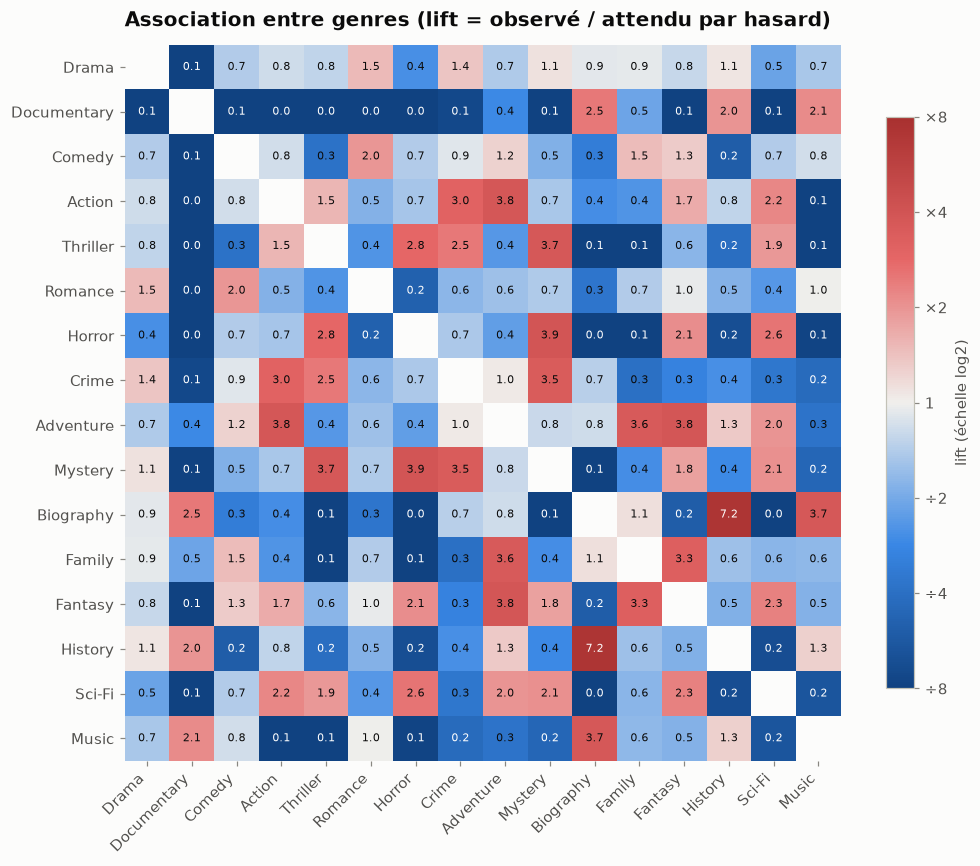

In [6]:
G = films.genres.str.get_dummies(sep=",")
top_genres = G.sum().sort_values(ascending=False).head(16).index
X = G[top_genres].astype(int)
co = X.T @ X                                   # nombre de films ayant les deux genres
p = X.mean()                                   # fréquence de chaque genre
arr = (co.to_numpy() / len(X)) / np.outer(p, p)  # > 1 : les deux genres vont plus souvent ensemble que par hasard
np.fill_diagonal(arr, np.nan)
lift = pd.DataFrame(arr, index=top_genres, columns=top_genres)
log_lift = np.log2(lift)

fig, ax = plt.subplots(figsize=(10.5, 9))
im = ax.imshow(log_lift.values, cmap=DIV, norm=TwoSlopeNorm(0, vmin=-3, vmax=3))
ax.set_xticks(range(len(top_genres)), top_genres, rotation=45, ha="right")
ax.set_yticks(range(len(top_genres)), top_genres)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(len(top_genres)):
    for j in range(len(top_genres)):
        v = lift.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7.5,
                    color="white" if abs(np.log2(v)) > 2 else INK)
cb = fig.colorbar(im, ax=ax, shrink=0.75, label="lift (échelle log2)")
cb.set_ticks([-3, -2, -1, 0, 1, 2, 3], labels=["÷8", "÷4", "÷2", "1", "×2", "×4", "×8"])
ax.set_title("Association entre genres (lift = observé / attendu par hasard)")
plt.show()

In [7]:
# Paires de genres les plus et les moins associées (au moins 500 films en commun pour les plus associées)
paires = pd.DataFrame({"lift": lift.stack(), "films": co.stack()})
paires = paires[[a < b for a, b in paires.index]]
display(paires[paires.films >= 500].nlargest(8, "lift").round(2))
paires.nsmallest(8, "lift").round(2)

,,lift,films
Biography,History,7.25,3340
Horror,Mystery,3.86,5094
Adventure,Fantasy,3.84,3042
Action,Adventure,3.77,10153
Biography,Music,3.71,1672
Mystery,Thriller,3.71,5601
Adventure,Family,3.60,3150
Crime,Mystery,3.47,4214


lift  films
Documentary Thriller     0.01    150
            Romance      0.02    269
Biography   Horror       0.04     51
            Sci-Fi       0.04     18
Documentary Horror       0.04    383
Action      Documentary  0.05    617
Documentary Sci-Fi       0.05    168
Music       Thriller     0.06     71

**Lecture.** Les genres forment des **familles** nettes. Biographie et histoire vont 7 fois plus souvent ensemble que par hasard, et l'on retrouve les blocs action–aventure–fantasy–science-fiction et horreur–mystère–thriller–crime. Le **documentaire est isolé** : il ne se combine presque jamais avec un genre de fiction (lift ≤ 0,05 avec thriller, romance, horreur, action), seulement avec biographie, histoire et musique.

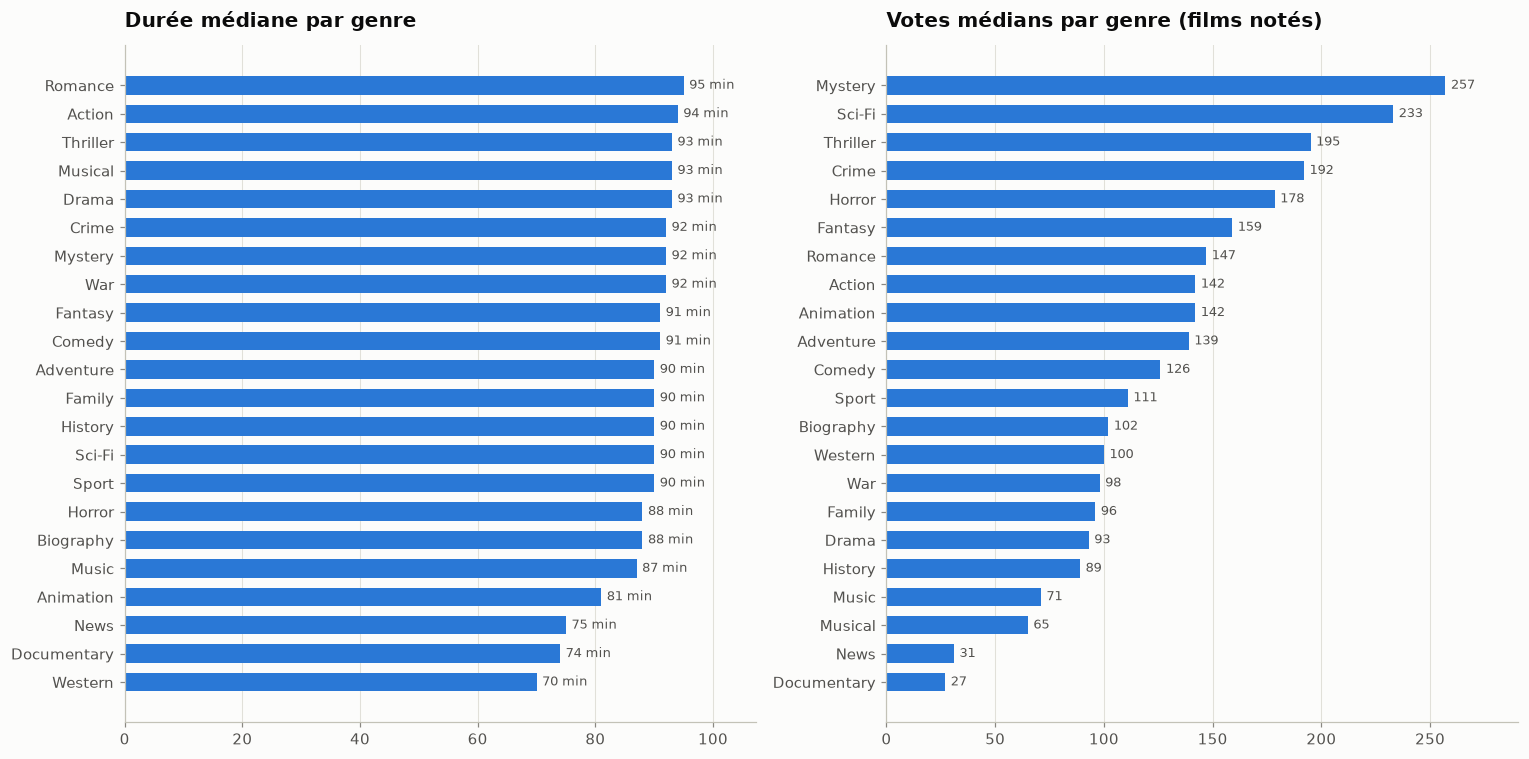

In [8]:
genres_films = films.assign(genre=films.genres.str.split(",")).explode("genre").dropna(subset=["genre"])
par_genre = genres_films.groupby("genre").agg(
    films=("tconst", "size"),
    duree_mediane=("runtimeMinutes", "median"),
    votes_medians=("numVotes", "median"),
    note_moyenne=("averageRating", "mean"),
).query("films >= 1000")

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
barh(par_genre.duree_mediane, "Durée médiane par genre", fmt="{:.0f} min", ax=axes[0])
barh(par_genre.votes_medians, "Votes médians par genre (films notés)", ax=axes[1])
fig.tight_layout()
plt.show()

**Lecture.** Les durées médianes varient peu d'un genre de fiction à l'autre (88–95 min). Les formats courts sont le western (70 min, beaucoup de séries B des années 1930–1950), le documentaire (74 min) et l'animation (81 min). La popularité varie beaucoup plus : un film à suspense ou de science-fiction reçoit 2 à 3 fois plus de votes qu'un drame, et **10 fois plus qu'un documentaire** (27 votes en médiane).

## 3. Les titres

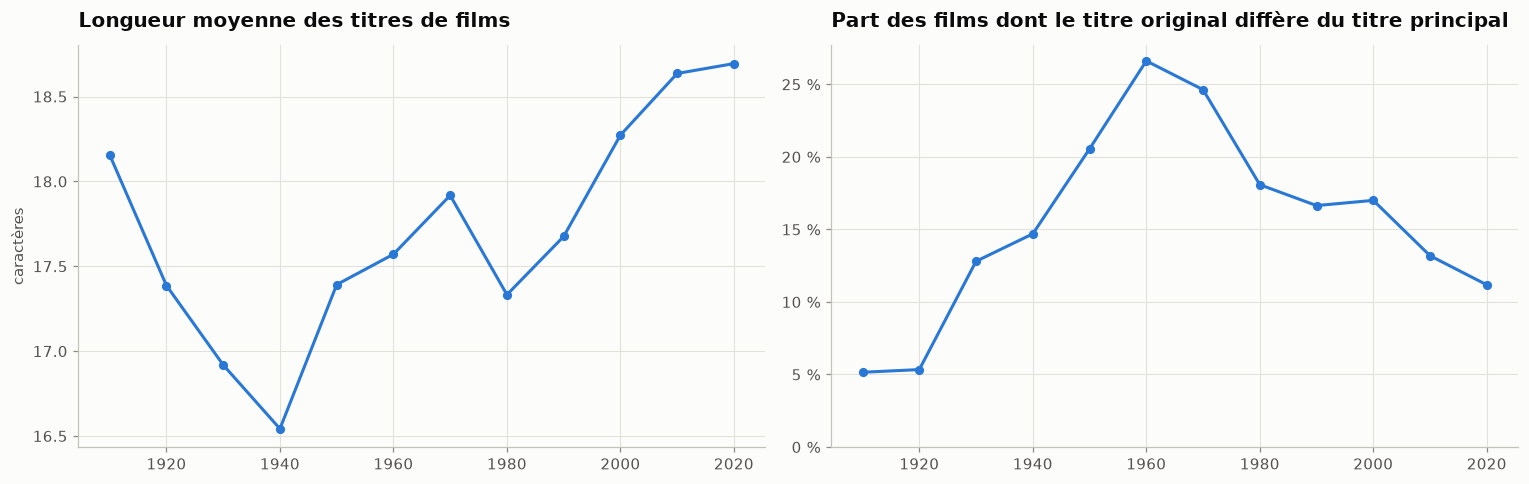

In [9]:
films["longueur_titre"] = films.primaryTitle.str.len()
films["nb_mots_titre"] = films.primaryTitle.str.split().str.len()
films["decennie"] = (films.startYear // 10) * 10
films["titre_etranger"] = films.originalTitle != films.primaryTitle

par_dec = (films[films.startYear.between(1910, ANNEE_MAX)]
           .groupby("decennie")
           .agg(mots_medians=("nb_mots_titre", "median"), longueur_moyenne=("longueur_titre", "mean"),
                part_titre_traduit=("titre_etranger", "mean")))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(par_dec.index, par_dec.longueur_moyenne, marker="o", markersize=5, color=BLEU)
axes[0].set_ylabel("caractères")
axes[0].set_title("Longueur moyenne des titres de films")
axes[1].plot(par_dec.index, 100 * par_dec.part_titre_traduit, marker="o", markersize=5, color=BLEU)
axes[1].yaxis.set_major_formatter(pourcent)
axes[1].set_ylim(0)
axes[1].set_title("Part des films dont le titre original diffère du titre principal")
fig.tight_layout()
plt.show()

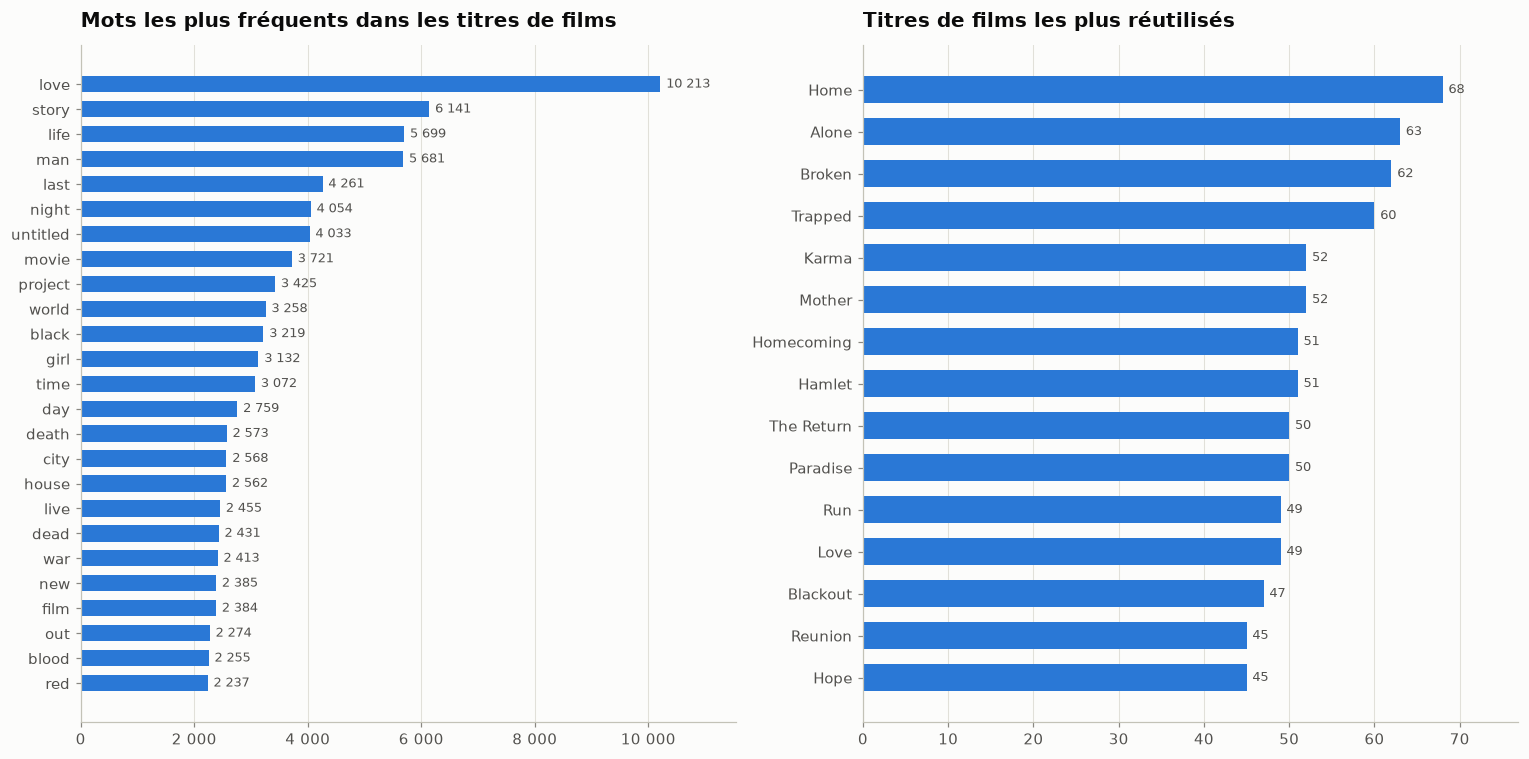

In [10]:
MOTS_VIDES = set('''the a an of and in to on for with at from by is it my your his her our their me you i we
    de la le les des du un une et en à au aux el los las del y il di da do der die das und ein
    no not be are was this that what who how why all one two part vs vol ii iii'''.split())
mots = (films.primaryTitle.str.lower()
        .str.findall(r"[a-zà-ÿ']{3,}")
        .explode()
        .loc[lambda s: ~s.isin(MOTS_VIDES)])
titres_repris = films.primaryTitle.value_counts().head(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
barh(mots.value_counts().head(25), "Mots les plus fréquents dans les titres de films", ax=axes[0])
barh(titres_repris, "Titres de films les plus réutilisés", ax=axes[1])
fig.tight_layout()
plt.show()

In [11]:
# Les mots qui montent et qui descendent : part des titres contenant le mot, avant 1970 vs après 2010
def part_mot(sous_ensemble):
    m = sous_ensemble.primaryTitle.str.lower().str.findall(r"[a-zà-ÿ']{3,}").explode()
    return m[~m.isin(MOTS_VIDES)].value_counts() / len(sous_ensemble)

avant, apres = part_mot(films[films.startYear < 1970]), part_mot(films[films.startYear >= 2010])
evol = pd.DataFrame({"avant_1970 (%)": 100 * avant, "depuis_2010 (%)": 100 * apres}).fillna(0)
evol = evol[(evol.max(axis=1) >= 0.25)]
evol["ratio"] = (evol["depuis_2010 (%)"] + 0.01) / (evol["avant_1970 (%)"] + 0.01)
print("Mots en forte hausse"); display(evol.nlargest(10, "ratio").round(2))
print("Mots en forte baisse"); evol.nsmallest(10, "ratio").round(2)

Mots en forte hausse


,avant_1970 (%),depuis_2010 (%),ratio
primaryTitle,,,
movie,0.02,0.75,29.52
documentary,0.00,0.26,22.98
christmas,0.03,0.36,10.12
film,0.06,0.40,5.82
american,0.07,0.33,4.29
journey,0.08,0.34,4.11
live,0.12,0.52,4.08
story,0.28,1.11,3.88
dead,0.09,0.37,3.81


Mots en forte baisse


,avant_1970 (%),depuis_2010 (%),ratio
primaryTitle,,,
onna,0.38,0.02,0.08
von,0.30,0.06,0.22
den,0.27,0.06,0.26
woman,0.59,0.17,0.30
lady,0.34,0.10,0.31
girl,0.68,0.35,0.52
three,0.33,0.17,0.53
men,0.35,0.19,0.55
man,1.00,0.70,0.71


**Lecture.** Les titres raccourcissent jusqu'aux années 1940, puis s'allongent régulièrement (18,7 caractères en moyenne aujourd'hui). La part des films dont le titre original diffère du titre principal (titres étrangers traduits) culmine dans les années 1960 (~27 %) et retombe à 11 %. **« Love »** est de loin le mot le plus fréquent. « Untitled » et « Project » viennent des projets pas encore titrés. Parmi les mots en hausse, on trouve *movie*, *documentary* et *christmas* (×10, l'effet des téléfilms de Noël) ; parmi les mots en baisse, *woman*, *lady*, *girl* et les mots japonais et allemands des catalogues anciens (*onna* = femme). Les titres les plus réutilisés sont des mots simples (*Home*, *Alone*, *Broken*) et *Hamlet* (51 adaptations).

## 4. Carrières des réalisateurs
Chaque film est rattaché à tous ses réalisateurs. Le **rang** d'un film = 1er, 2e, 3e… film du réalisateur (par année de sortie).

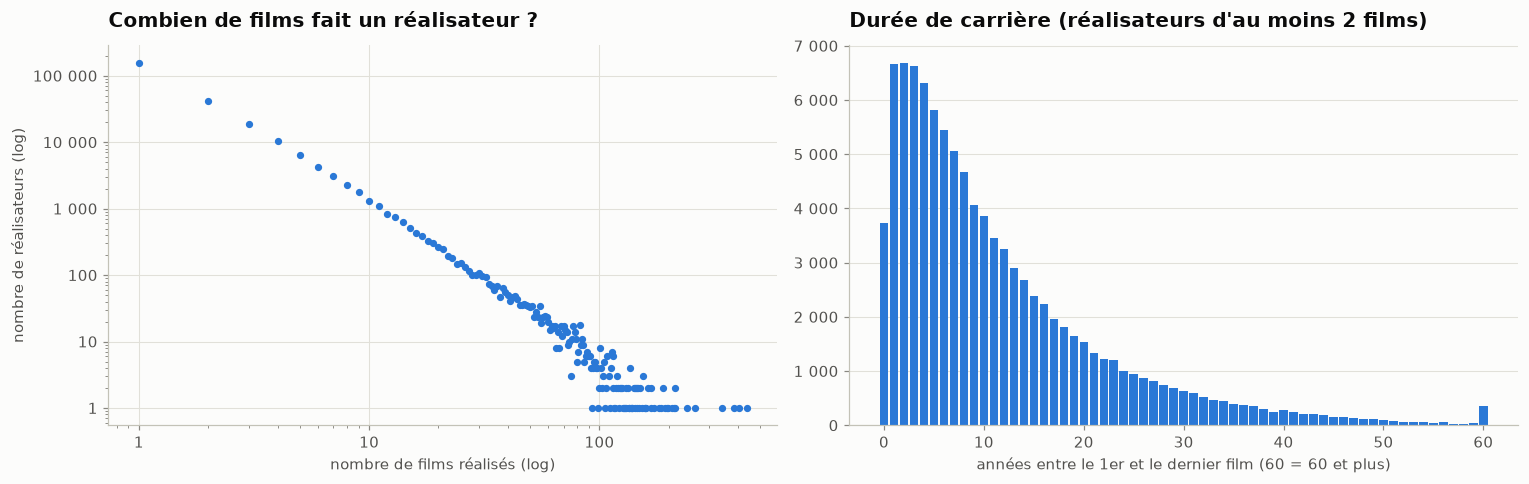

256,081 réalisateurs ; 62 % n'ont réalisé qu'un seul film ; durée de carrière médiane (≥ 2 films) : 8 ans


In [12]:
real = (eclater(films[films.startYear.notna()], "directors", "realisateur")
        [["tconst", "realisateur", "startYear", "averageRating", "numVotes", "director1BirthYear", "position"]]
        .sort_values(["realisateur", "startYear", "tconst"]))
real["rang"] = real.groupby("realisateur").cumcount() + 1
carrieres = real.groupby("realisateur").agg(films=("tconst", "size"), debut=("startYear", "min"),
                                            fin=("startYear", "max"))
carrieres["duree_carriere"] = carrieres.fin - carrieres.debut

nb = carrieres.films.value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(nb.index, nb.values, s=14, color=BLEU)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].xaxis.set_major_formatter(milliers); axes[0].yaxis.set_major_formatter(milliers)
axes[0].set_xlabel("nombre de films réalisés (log)")
axes[0].set_ylabel("nombre de réalisateurs (log)")
axes[0].set_title("Combien de films fait un réalisateur ?")
d = carrieres[carrieres.films >= 2].duree_carriere.clip(upper=60).value_counts().sort_index()
axes[1].bar(d.index, d.values, width=0.85, color=BLEU)
axes[1].yaxis.set_major_formatter(milliers)
axes[1].grid(axis="x", visible=False)
axes[1].set_xlabel("années entre le 1er et le dernier film (60 = 60 et plus)")
axes[1].set_title("Durée de carrière (réalisateurs d'au moins 2 films)")
fig.tight_layout()
plt.show()
part1 = (carrieres.films == 1).mean()
print(f"{len(carrieres):,} réalisateurs ; {100 * part1:.0f} % n'ont réalisé qu'un seul film ; "
      f"durée de carrière médiane (≥ 2 films) : {carrieres[carrieres.films >= 2].duree_carriere.median():.0f} ans")

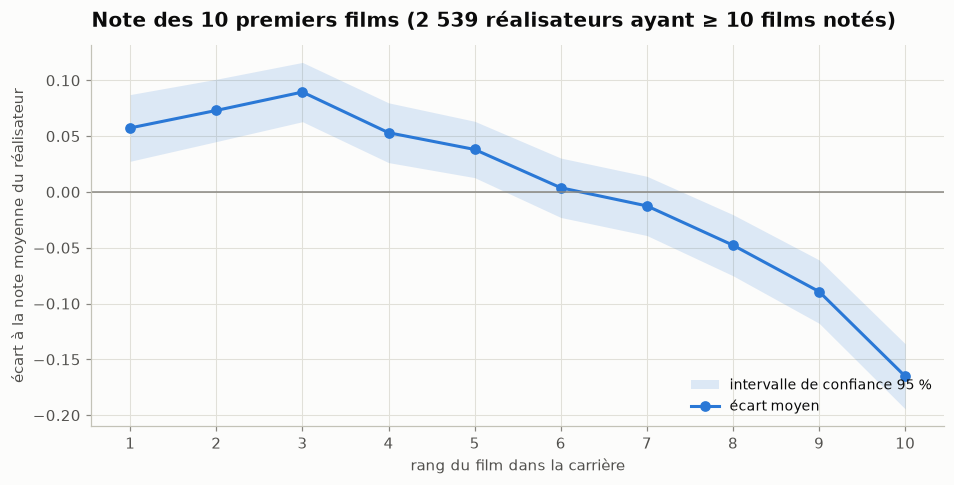

In [13]:
# Note selon le rang du film, pour les réalisateurs ayant au moins 10 films notés (panel équilibré sur les 10 premiers)
real_notes = real[real.averageRating.notna() & (real.numVotes >= 100)].copy()
real_notes["rang_note"] = real_notes.groupby("realisateur").cumcount() + 1
eligibles = real_notes.groupby("realisateur").size().loc[lambda s: s >= 10].index
panel = real_notes[real_notes.realisateur.isin(eligibles) & (real_notes.rang_note <= 10)]
# Note relative : écart à la moyenne du réalisateur sur ses 10 premiers films
panel = panel.assign(ecart=panel.averageRating - panel.groupby("realisateur").averageRating.transform("mean"))
courbe = panel.groupby("rang_note").ecart.agg(["mean", "sem"])

fig, ax = plt.subplots()
ax.fill_between(courbe.index, courbe["mean"] - 1.96 * courbe["sem"], courbe["mean"] + 1.96 * courbe["sem"],
                color=BLEU, alpha=0.15, linewidth=0, label="intervalle de confiance 95 %")
ax.plot(courbe.index, courbe["mean"], marker="o", markersize=6, color=BLEU, label="écart moyen")
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_xticks(range(1, 11))
ax.set_xlabel("rang du film dans la carrière")
ax.set_ylabel("écart à la note moyenne du réalisateur")
ax.set_title(f"Note des 10 premiers films ({len(eligibles):,} réalisateurs ayant ≥ 10 films notés)".replace(",", " "))
ax.legend(loc="lower right")
plt.show()

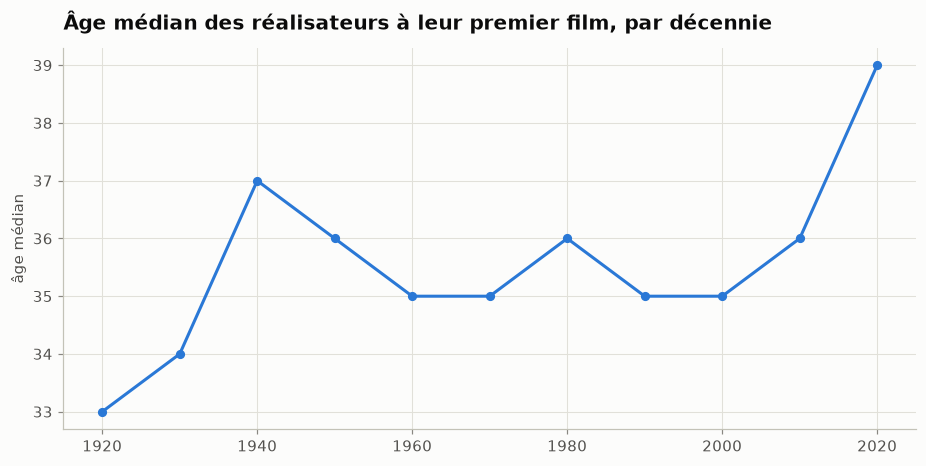

In [14]:
# Âge au premier film, par décennie de début
premiers = real[real.rang == 1].copy()
premiers["age_premier_film"] = premiers.startYear - premiers.director1BirthYear
premiers = premiers[(premiers.position == 0) & premiers.age_premier_film.between(15, 90)]
age_dec = premiers.groupby((premiers.startYear // 10) * 10).age_premier_film.median().loc[1920:ANNEE_MAX]
fig, ax = plt.subplots()
ax.plot(age_dec.index, age_dec.values, marker="o", markersize=5, color=BLEU)
ax.set_ylabel("âge médian")
ax.set_title("Âge médian des réalisateurs à leur premier film, par décennie")
plt.show()

**Lecture.** La distribution du nombre de films par réalisateur suit une **loi de puissance** (droite sur l'échelle log-log) : **62 % des 256 000 réalisateurs n'ont fait qu'un film**, et la carrière médiane de ceux qui en font au moins deux est de 8 ans. Chez les réalisateurs prolifiques (≥ 10 films notés), **les premiers films sont les mieux notés** : un pic au 3ᵉ film (+0,09 point au-dessus de leur moyenne), puis une baisse régulière jusqu'au 10ᵉ film (−0,17). L'âge médian au premier film est stable autour de 35 ans depuis 1950, mais remonte nettement dans les années 2020 (39 ans).

## 5. Collaborations
Paires de personnes qui travaillent ensemble sur le plus grand nombre de films.
Pour les acteurs, on se limite aux 4 premiers crédités (rôles principaux).

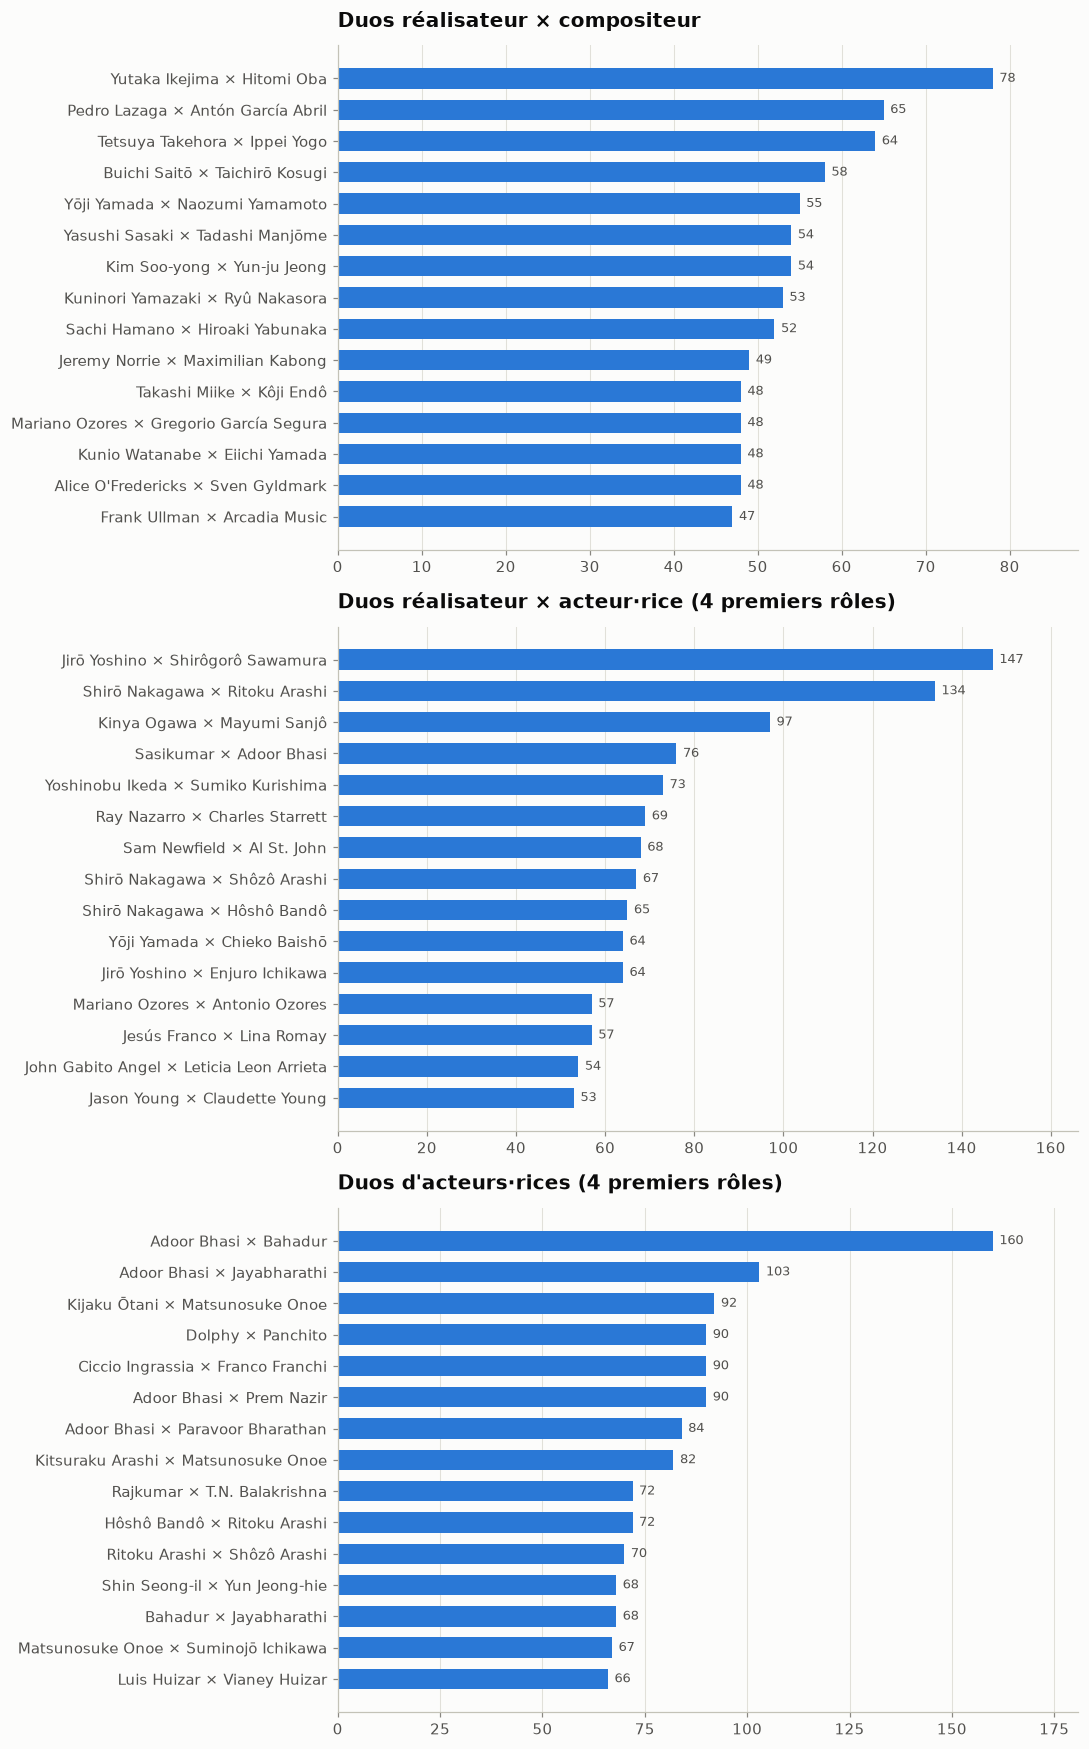

In [15]:
r = eclater(films, "directors", "realisateur")[["tconst", "realisateur"]]
comp = eclater(films, "composers", "compositeur")[["tconst", "compositeur"]]
act = eclater(films, "actors", "acteur").query("position < 4")[["tconst", "acteur"]]

duo_rc = r.merge(comp, on="tconst").query("realisateur != compositeur")
duo_ra = r.merge(act, on="tconst").query("realisateur != acteur")
duo_aa = act.merge(act, on="tconst", suffixes=("_1", "_2")).query("acteur_1 < acteur_2")


def top_duos(d, a, b, n=15):
    s = d.groupby([a, b]).size().nlargest(n)
    return s.set_axis([f"{x} × {y}" for x, y in s.index])


fig, axes = plt.subplots(3, 1, figsize=(10, 16))
barh(top_duos(duo_rc, "realisateur", "compositeur"), "Duos réalisateur × compositeur", ax=axes[0])
barh(top_duos(duo_ra, "realisateur", "acteur"), "Duos réalisateur × acteur·rice (4 premiers rôles)", ax=axes[1])
barh(top_duos(duo_aa, "acteur_1", "acteur_2"), "Duos d'acteurs·rices (4 premiers rôles)", ax=axes[2])
fig.tight_layout()
plt.show()

In [16]:
# Duos réalisateur × compositeur parmi les films populaires (chaque film ≥ 50 000 votes)
populaires = set(films.loc[films.numVotes >= 50_000, "tconst"])
(duo_rc[duo_rc.tconst.isin(populaires)].groupby(["realisateur", "compositeur"]).size()
 .nlargest(12).rename("films populaires ensemble").to_frame())

,,films populaires ensemble
realisateur,compositeur,
Steven Spielberg,John Williams,27
Robert Zemeckis,Alan Silvestri,17
Tim Burton,Danny Elfman,17
Ethan Coen,Carter Burwell,16
Joel Coen,Carter Burwell,16
David Cronenberg,Howard Shore,11
Hayao Miyazaki,Joe Hisaishi,11
Clint Eastwood,Lennie Niehaus,8
M. Night Shyamalan,James Newton Howard,8


**Lecture.** En volume brut, les duos les plus fidèles viennent de systèmes de production en série : studios japonais (*pinku eiga*, films de sabre), cinéma malayalam (Adoor Bhasi × Bahadur, 160 films ensemble), comédies italiennes (Franco & Ciccio). Sur les films populaires, on retrouve les **grands tandems** du cinéma : **Spielberg × John Williams (27 films)**, Zemeckis × Silvestri, Burton × Elfman, les frères Coen × Carter Burwell, Cronenberg × Howard Shore, Miyazaki × Joe Hisaishi.

## 6. Acteurs et actrices : régularité et longévité

In [17]:
acteurs = eclater(films[films.startYear.notna()], "actors", "acteur")
stats_act = acteurs.groupby("acteur").agg(
    films=("tconst", "size"),
    films_notes=("averageRating", "count"),
    note_moyenne=("averageRating", "mean"),
    votes_total=("numVotes", "sum"),
    debut=("startYear", "min"), fin=("startYear", "max"),
    part_premier_role=("position", lambda s: (s == 0).mean()),
)

# Les mieux notés parmi les acteurs ayant au moins 15 films avec ≥ 10 000 votes chacun
solides = acteurs[acteurs.numVotes >= 10_000].groupby("acteur").agg(
    films=("tconst", "size"), note_moyenne=("averageRating", "mean"), votes_total=("numVotes", "sum"))
print("Acteurs·rices les mieux notés (au moins 15 films ayant chacun ≥ 10 000 votes)")
tableau(solides[solides.films >= 15].nlargest(20, "note_moyenne"),
        {"note_moyenne": "{:.2f}", "votes_total": "{:,.0f}"})

Acteurs·rices les mieux notés (au moins 15 films ayant chacun ≥ 10 000 votes)


,films,note_moyenne,votes_total
acteur,,,
Kemal Sunal,19,8.41,363 928
Şener Şen,17,8.35,406 093
Graham Chapman,15,7.78,3 668 094
Terry Gilliam,15,7.78,3 668 094
Toshirō Mifune,20,7.76,1 366 754
Alec Guinness,18,7.72,4 138 031
Terry Jones,16,7.68,3 683 451
Humphrey Bogart,24,7.57,1 609 985
James Stewart,28,7.57,2 630 636


In [18]:
# NB : une « longévité » calculée sur les noms serait faussée par les homonymes (carrières de 110 ans).
# On regarde plutôt qui tient le plus souvent le premier rôle (1er crédité).
stats_act["premiers_roles"] = (stats_act.films * stats_act.part_premier_role).round().astype(int)
print("Acteurs·rices ayant tenu le plus de premiers rôles (1er crédité)")
tableau(stats_act.nlargest(15, "premiers_roles")[["films", "premiers_roles", "part_premier_role", "debut", "fin",
                                                   "note_moyenne"]],
        {"part_premier_role": "{:.0%}", "debut": "{:.0f}", "fin": "{:.0f}", "note_moyenne": "{:.2f}"})

Acteurs·rices ayant tenu le plus de premiers rôles (1er crédité)


,films,premiers_roles,part_premier_role,debut,fin,note_moyenne
acteur,,,,,,
Matsunosuke Onoe,565,524,93%,1910,1926,5.25
Mohanlal,399,296,74%,1978,2027,6.40
Brahmanandam,1129,283,25%,1987,2026,5.96
Shin Seong-il,419,278,66%,1960,2013,5.83
Mammootty,434,254,59%,1979,2027,6.47
Fernando Poe Jr.,260,229,88%,1954,2003,6.77
Kazuo Hasegawa,307,225,73%,1927,1963,6.56
Cüneyt Arkın,314,224,71%,1964,2014,5.29
Sivaji Ganesan,344,210,61%,1952,1999,6.69


In [19]:
print("Acteurs·rices les plus vus (votes cumulés sur leurs films)")
tableau(stats_act.nlargest(15, "votes_total")[["films", "votes_total", "note_moyenne", "part_premier_role"]],
        {"votes_total": "{:,.0f}", "note_moyenne": "{:.2f}", "part_premier_role": "{:.0%}"})

Acteurs·rices les plus vus (votes cumulés sur leurs films)


,films,votes_total,note_moyenne,part_premier_role
acteur,,,,
Scarlett Johansson,67,27 137 607,6.86,27%
Samuel L. Jackson,118,24 934 009,6.33,26%
Robert Downey Jr.,71,23 651 262,6.53,34%
Brad Pitt,57,22 277 644,6.95,54%
Mark Ruffalo,61,21 528 783,6.90,20%
Chris Evans,52,21 204 846,6.75,23%
Morgan Freeman,94,20 475 891,6.46,28%
Tom Hanks,70,20 463 306,6.92,71%
Leonardo DiCaprio,36,20 388 509,7.20,69%


**Lecture.** Parmi les acteurs ayant au moins 15 films très votés, les mieux notés sont deux stars de la comédie turque (**Kemal Sunal, Şener Şen**, plus de 8,3), les Monty Python, puis les classiques Mifune, Guinness, Bogart et James Stewart. En **votes cumulés**, c'est l'effet Marvel : Scarlett Johansson, Samuel L. Jackson et Robert Downey Jr. dépassent chacun 23 millions de votes. DiCaprio a la meilleure note moyenne de ce groupe (7,2) et tient le premier rôle dans 69 % de ses films. Le record de premiers rôles revient à **Matsunosuke Onoe**, première star du cinéma japonais muet (524 premiers rôles entre 1910 et 1926). Mohanlal et Mammootty dominent le cinéma malayalam.

## 7. Séries : la note évolue-t-elle au fil des saisons ?
Pour chaque série (≥ 20 000 votes, ≥ 4 saisons), on calcule la note moyenne des épisodes de chaque saison,
puis l'écart à la moyenne de la série.

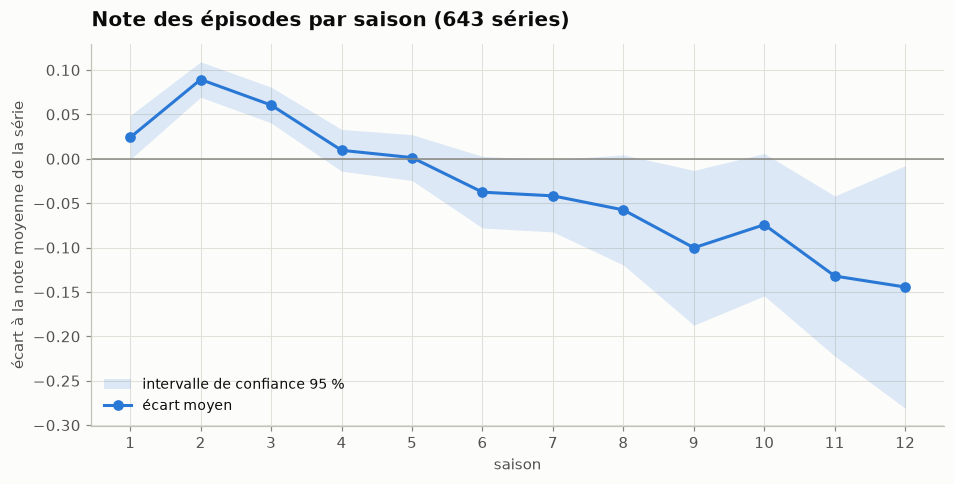

In [20]:
series = df[df.titleType.isin(["tvSeries", "tvMiniSeries"])].set_index("tconst")
ep = df[(df.titleType == "tvEpisode") & df.averageRating.notna() & df.seasonNumber.between(1, 50)]
saisons = (ep.groupby(["parentTconst", "seasonNumber"])
           .agg(note=("averageRating", "mean"), episodes=("tconst", "size")).reset_index())
saisons = saisons.join(series[["primaryTitle", "numVotes"]], on="parentTconst")
saisons["nb_saisons"] = saisons.groupby("parentTconst").seasonNumber.transform("max")
grandes = saisons[(saisons.numVotes >= 20_000) & (saisons.nb_saisons >= 4) & (saisons.episodes >= 3)].copy()
grandes["ecart"] = grandes.note - grandes.groupby("parentTconst").note.transform("mean")
courbe_s = grandes[grandes.seasonNumber <= 12].groupby("seasonNumber").ecart.agg(["mean", "sem", "size"])

fig, ax = plt.subplots()
ax.fill_between(courbe_s.index, courbe_s["mean"] - 1.96 * courbe_s["sem"], courbe_s["mean"] + 1.96 * courbe_s["sem"],
                color=BLEU, alpha=0.15, linewidth=0, label="intervalle de confiance 95 %")
ax.plot(courbe_s.index, courbe_s["mean"], marker="o", markersize=6, color=BLEU, label="écart moyen")
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_xticks(courbe_s.index)
ax.set_xlabel("saison")
ax.set_ylabel("écart à la note moyenne de la série")
ax.set_title(f"Note des épisodes par saison ({grandes.parentTconst.nunique():,} séries)".replace(",", " "))
ax.legend(loc="lower left")
plt.show()

In [21]:
# Séries dont la note a le plus chuté (ou progressé) entre la 1re et la dernière saison
bornes = (grandes.sort_values("seasonNumber").groupby("parentTconst")
          .agg(serie=("primaryTitle", "first"), saisons=("seasonNumber", "max"),
               premiere=("note", "first"), derniere=("note", "last"), votes=("numVotes", "first")))
bornes["evolution"] = bornes.derniere - bornes.premiere
bornes = bornes[bornes.votes >= 100_000]
fmt = {"premiere": "{:.2f}", "derniere": "{:.2f}", "evolution": "{:+.2f}", "votes": "{:,.0f}"}
print("Plus fortes chutes (séries ≥ 100 000 votes)")
display(tableau(bornes.nsmallest(10, "evolution"), fmt).set_index("serie"))
print("Plus fortes progressions")
tableau(bornes.nlargest(10, "evolution"), fmt).set_index("serie")

Plus fortes chutes (séries ≥ 100 000 votes)


,saisons,premiere,derniere,votes,evolution
serie,,,,,
House of Cards,6,8.38,4.19,563 340,-4.20
The Witcher,4,8.29,4.39,625 168,-3.90
True Detective,4,9.24,6.43,769 839,-2.80
American Horror Story,12,7.99,5.32,364 707,-2.67
Game of Thrones,8,8.98,6.40,2 661 163,-2.58
The Flash,9,8.56,6.02,388 661,-2.54
Two and a Half Men,12,7.91,5.39,300 889,-2.52
13 Reasons Why,4,8.32,6.10,343 198,-2.22
Killing Eve,4,8.36,6.42,155 834,-1.94


Plus fortes progressions


,saisons,premiere,derniere,votes,evolution
serie,,,,,
My Hero Academia,8,8.08,9.40,127 052,+1.32
Parks and Recreation,7,7.15,8.25,319 267,+1.10
BoJack Horseman,6,7.83,8.81,238 857,+0.98
Succession,4,8.24,9.13,367 348,+0.89
Seinfeld,9,7.34,8.21,388 600,+0.87
Star Wars: The Clone Wars,7,7.33,8.10,148 384,+0.77
Schitt's Creek,6,7.50,8.26,176 992,+0.76
Adventure Time,10,7.44,8.19,136 393,+0.76
Justified,6,8.05,8.71,132 575,+0.66


In [22]:
print("Épisodes les mieux notés (au moins 50 000 votes)")
top_ep = ep[ep.numVotes >= 50_000].nlargest(15, "averageRating")
tableau(top_ep[["parentTitle", "seasonNumber", "episodeNumber", "primaryTitle", "averageRating", "numVotes"]],
        {"numVotes": "{:,.0f}"}).set_index("parentTitle")

Épisodes les mieux notés (au moins 50 000 votes)


,seasonNumber,episodeNumber,primaryTitle,averageRating,numVotes
parentTitle,,,,,
Better Call Saul,6,7,Plan and Execution,9.9,89 274
Game of Thrones,3,9,The Rains of Castamere,9.9,187 517
Invincible,3,8,I Thought You'd Never Shut Up,9.9,100 494
Invincible,4,7,Don't Do Anything Rash,9.9,52 653
Game of Thrones,6,9,Battle of the Bastards,9.9,314 473
Game of Thrones,6,10,The Winds of Winter,9.9,232 695
Attack on Titan,3,18,Midnight Sun,9.8,99 152
Attack on Titan,3,20,That Day,9.8,78 828
Better Call Saul,6,13,Saul Gone,9.8,81 442


**Lecture.** Sur 643 séries longues et populaires, les épisodes sont en moyenne **les mieux notés en saison 2** (+0,09 point), puis la note baisse régulièrement après la 5ᵉ saison (−0,14 vers les saisons 11–12). C'est l'usure classique, avec une incertitude qui grandit car peu de séries durent aussi longtemps. Les chutes spectaculaires : **House of Cards** (8,4 → 4,2), *The Witcher*, *True Detective* et *Game of Thrones* (9,0 → 6,4). À l'inverse, *My Hero Academia*, *Parks and Recreation*, *BoJack Horseman* et *Succession* se sont bonifiées. Les épisodes les mieux notés de toute la base sont des finales ou des épisodes-clés de *Better Call Saul*, *Game of Thrones* et *Attack on Titan*.

## 8. Profil des films à succès
On compare trois groupes de films notés selon leur nombre de votes :
**confidentiels** (< 1 000), **intermédiaires** (1 000 – 100 000) et **à succès** (≥ 100 000).

In [23]:
profil = notes.assign(
    groupe=pd.cut(notes.numVotes, [0, 999, 99_999, np.inf],
                  labels=["confidentiel", "intermédiaire", "à succès"]),
    nb_genres=notes.genres.str.count(",") + 1,
    titre_fr=notes.frenchTitle.notna(),
    part_actrices=notes.numActresses / notes.numActors.replace(0, pd.NA),
)
resume = profil.groupby("groupe", observed=True).agg(
    films=("tconst", "size"),
    annee_mediane=("startYear", "median"),
    duree_mediane=("runtimeMinutes", "median"),
    note_moyenne=("averageRating", "mean"),
    nb_genres_moyen=("nb_genres", "mean"),
    pays_medians=("numRegions", "median"),
    part_titre_fr=("titre_fr", "mean"),
    part_actrices=("part_actrices", "mean"),
)
tableau(resume, {"films": "{:,.0f}", "annee_mediane": "{:.0f}", "duree_mediane": "{:.0f} min",
                 "note_moyenne": "{:.2f}", "nb_genres_moyen": "{:.2f}", "pays_medians": "{:.0f}",
                 "part_titre_fr": "{:.0%}", "part_actrices": "{:.0%}"}).T

groupe,confidentiel,intermédiaire,à succès
films,294 674,46 314,2 750
annee_mediane,2008,2009,2009
duree_mediane,90 min,100 min,113 min
note_moyenne,6.15,6.19,6.99
nb_genres_moyen,1.66,2.31,2.67
pays_medians,6,20,48
part_titre_fr,14%,66%,100%
part_actrices,35%,35%,32%


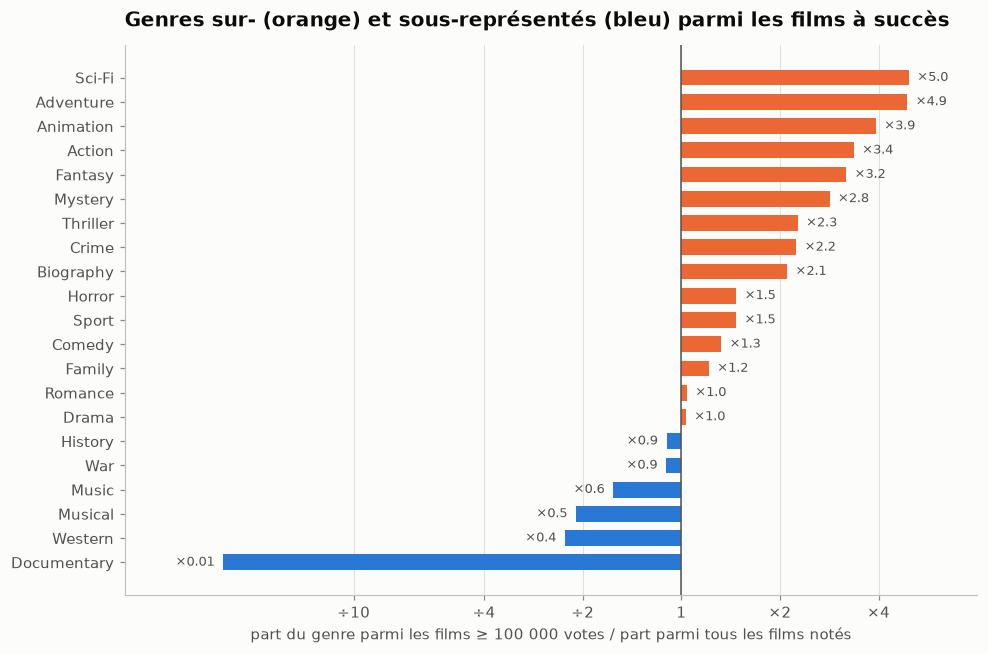

In [24]:
# Sur-représentation des genres parmi les films à succès (part chez les succès / part chez tous les films notés)
Gn = notes.genres.str.get_dummies(sep=",")
succes = notes.numVotes >= 100_000
ratio = (Gn[succes].mean() / Gn.mean()).loc[lambda s: Gn.sum() >= 2000].sort_values()
fig, ax = plt.subplots(figsize=(10, 6.5))
couleurs = [ORANGE if v >= 1 else BLEU for v in ratio.values]
affiche = ratio.clip(lower=0.04)  # plafonné à l'affichage (documentaire ≈ 0) ; la vraie valeur est écrite
ax.barh(ratio.index, affiche.values - 1, left=1, height=0.65, color=couleurs)
ax.axvline(1, color=INK2, linewidth=1)
ax.set_xscale("log")
ax.grid(axis="y", visible=False)
for y, (v, va) in enumerate(zip(ratio.values, affiche.values)):
    ax.text(va * (1.06 if v >= 1 else 0.94), y, f"×{v:.2f}" if v < 0.1 else f"×{v:.1f}", va="center",
            ha="left" if v >= 1 else "right", fontsize=8.5, color=INK2)
ax.set_xlim(0.02, 8)
ax.set_xticks([0.1, 0.25, 0.5, 1, 2, 4], ["÷10", "÷4", "÷2", "1", "×2", "×4"])
ax.minorticks_off()
ax.set_title("Genres sur- (orange) et sous-représentés (bleu) parmi les films à succès")
ax.set_xlabel("part du genre parmi les films ≥ 100 000 votes / part parmi tous les films notés")
plt.show()

**Lecture.** Les **2 750 films à succès** (≥ 100 000 votes) se distinguent nettement : ils sont plus longs (113 min contre 90), mieux notés (7,0 contre 6,15), associent plus de genres (2,7 contre 1,7), sont diffusés dans 48 pays en médiane (contre 6), et **ont tous un titre français**. La part des actrices y est un peu plus faible (32 % contre 35 %). Les genres les plus sur-représentés sont la **science-fiction et l'aventure (×5)**, l'animation, l'action et la fantasy. Le documentaire en est quasiment absent, et le western et la comédie musicale sont sous-représentés.

## 9. Synthèse

| Thème | Principaux constats |
|---|---|
| **Classement** | La note brute est trompeuse pour les films peu votés ; la moyenne bayésienne (m = 25 000) retrouve les classiques. |
| **Genres** | Des familles nettes (action–aventure–SF, horreur–mystère–thriller, biographie–histoire) ; le documentaire est isolé, très peu voté et en forte croissance. |
| **Titres** | Des titres plus longs depuis 1940 ; « love » domine ; la part des titres étrangers traduits baisse depuis les années 1960. |
| **Réalisateurs** | Loi de puissance : 62 % ne font qu'un film ; chez les prolifiques, les premiers films sont les mieux notés. |
| **Collaborations** | Les grands tandems réalisateur–compositeur (Spielberg–Williams, Burton–Elfman, Miyazaki–Hisaishi) ressortent sur les films populaires. |
| **Acteurs** | Votes cumulés dominés par le casting Marvel ; meilleures notes pour la comédie turque, les Monty Python et les classiques. |
| **Séries** | La note culmine en saison 2 puis s'use ; quelques effondrements célèbres (House of Cards, Game of Thrones). |
| **Succès** | Films à succès plus longs, multi-genres, très diffusés, portés par la SF, l'aventure et l'animation. |

**Limites** : les personnes sont identifiées par leur nom (les homonymes sont regroupés), les votes IMDb reflètent un public particulier, et les analyses de carrière ne portent que sur les films présents et datés dans IMDb.